In [1]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Create dummy data
	# The output of make_classification consists of feature data X and labels y
	# The labels y will be encoded (numerical) data
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# By default, make_classification produces float values
	# We need to convert them to discrete form

	# Take the absolute value of the values
	X = np.absolute(X)

	# Round values to two decimal places
	# Multiply by 100 so that there are no decimal points
	X = np.round(X, 2) * 100

	# Convert to integer type
	X = X.astype(int)

	# Check the result
	print(X)
	print(y)

[[112  83]
 [189 119]
 [ 89 111]
 [ 65  82]
 [225 147]
 [184  98]
 [ 95  91]
 [ 16 101]
 [ 32  24]
 [ 99  99]
 [ 24  56]
 [ 96  12]
 [159 136]
 [133 124]
 [160 133]
 [242 183]
 [127 106]
 [ 67 173]
 [ 91 112]
 [ 89 270]
 [ 95   7]
 [ 85 166]
 [113  24]
 [120 103]
 [  8 187]
 [ 66 148]
 [ 76 138]
 [127 123]
 [125  51]
 [ 48 154]]
[0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [2]:

import pandas as pd

# Reshape label y into 2D
# This is done because we will concatenate it with the feature data X
y_new = y.reshape(len(y), 1)

# Concatenate features X and label y into an array
data = np.concatenate((X, y_new), axis=1)

# Define column names
nama_kolom = ['Feature 1', 'Feature 2', 'Label']

# Create DataFrame
df = pd.DataFrame(data, columns=nama_kolom)

# Inspect the DataFrame
df.head()

,Feature 1,Feature 2,Label
0,112,83,0
1,189,119,0
2,89,111,0
3,65,82,0
4,225,147,0


In [3]:
	# Define label names
	labels = {
	    1 : 'Class A',
	    0 : 'Class B'
	}

	# Copy the DataFrame to create a new DataFrame
	# with more readable labels
	df_label = df.copy()

	# Replace labels using the Pandas mapping function
	# on the df_label DataFrame
	df_label['Label'] = df_label['Label'].map(labels)

	# Inspect the df_label DataFrame
	df_label.head()

,Feature 1,Feature 2,Label
0,112,83,Class B
1,189,119,Class B
2,89,111,Class B
3,65,82,Class B
4,225,147,Class B


In [4]:
	# Define label names
	labels = {
	    1 : 'Class A',
	    0 : 'Class B'
	}

	# Copy the DataFrame to create a new DataFrame
	# with more readable labels
	df_label = df.copy()

	# Replace labels using the Pandas mapping function
	# on the df_label DataFrame
	df_label['Label'] = df_label['Label'].map(labels)

	# Inspect the df_label DataFrame
	df_label.head()

,Feature 1,Feature 2,Label
0,112,83,Class B
1,189,119,Class B
2,89,111,Class B
3,65,82,Class B
4,225,147,Class B


/tmp/ipykernel_3690/1990124180.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Class A')
/tmp/ipykernel_3690/1990124180.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Class B')


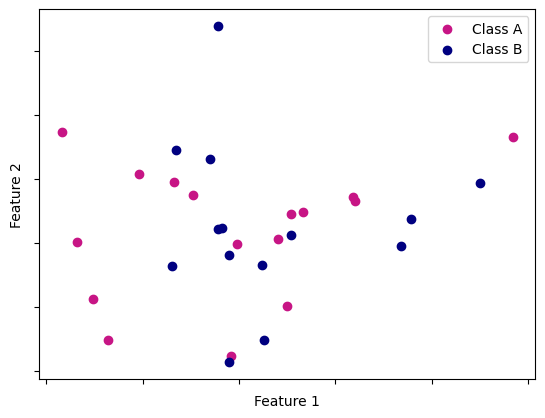

In [5]:
	import matplotlib.pyplot as plt

	# Define colors for each class
	colors = {
	    'class_a': 'MediumVioletRed',
	    'class_b': 'Navy'
	}

	# Group labels by class name
	gb = df_label.groupby(['Label'])
	class_a = gb.get_group('Class A')
	class_b = gb.get_group('Class B')

	# Plot
	plt.scatter(x=class_a['Feature 1'], y=class_a['Feature 2'], c=colors['class_a'])
	plt.scatter(x=class_b['Feature 1'], y=class_b['Feature 2'], c=colors['class_b'])
	plt.xlabel('Feature 1')
	plt.ylabel('Feature 2')
	plt.legend(['Class A', 'Class B'])
	plt.gca().axes.xaxis.set_ticklabels([])
	plt.gca().axes.yaxis.set_ticklabels([])
	plt.show()

In [6]:
	from sklearn.naive_bayes import MultinomialNB # class for the MultinomialNB model
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluate the model using accuracy

	# Instantiate a MultinomialNB object
	mnb = MultinomialNB()

	# We can directly use the feature matrix X and labels y
	# resulting from the dummy data generation process

	# Split training and testing data
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit the model
	# The label y must be in 1D form or (n_samples,)
	mnb.fit(X_train, y_train)

	# Predict on training data
	y_train_pred = mnb.predict(X_train)

	# Evaluate training accuracy
	acc_train = accuracy_score(y_train, y_train_pred)

	# Predict test data
	y_test_pred = mnb.predict(X_test)

	# Evaluate the model using the accuracy metric
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print evaluation results
	print(f'Training accuracy: {acc_train}')
	print(f'Test accuracy: {acc_test}')

Training accuracy: 0.42857142857142855
Test accuracy: 0.6666666666666666


In [7]:
	from sklearn.naive_bayes import GaussianNB # class for the GaussianNB model

	# Instantiate a Gaussian object
	gnb = GaussianNB()

	# We use the same training and testing split
	# as used for the multinomial model

	# Fit the model
	# The label y must be in 1D form or (n_samples,)
	gnb.fit(X_train, y_train)

	# Predict on training data
	y_train_pred_gnb = gnb.predict(X_train)

	# Evaluate training accuracy
	acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

	# Predict test data
	y_test_pred_gnb = gnb.predict(X_test)

	# Evaluate the model using the accuracy metric
	acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

	# Print evaluation results
	print(f'Training accuracy (Gaussian): {acc_train_gnb}')
	print(f'Test accuracy (Gaussian): {acc_test_gnb}')

Training accuracy (Gaussian): 0.6190476190476191
Test accuracy (Gaussian): 0.2222222222222222
